# Credit Card Fraud Detection Using Machine Learning

## Project Overview
This project focuses on identifying potentially fraudulent credit card transactions using Machine Learning in Python.

The objective is to build a classification model that can distinguish between legitimate and fraudulent transactions using historical transaction data.

## Project Objectives
- Understand and investigate credit card transaction data.
- Perform data cleaning and preprocessing.
- Build a Logistic Regression classification model.
- Evaluate model performance using Accuracy, Precision, Recall and F1 Score.
- Investigate incorrectly classified transactions to understand the model's limitations.

## Dataset
The project uses a publicly available credit card fraud detection dataset containing transaction information and a target variable called `Class`.

- 0 = Legitimate transaction
- 1 = Fraudulent transaction

## Tools and Libraries
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib
- Scikit-learn

## Model Used
Logistic Regression

## Project Scope
This model is developed for educational purposes & skill enhancement.
Building this helped me understand the process behind development of a Machine Learning model.

In [201]:
print("Hello! I am building my first Machine Learning project.")

Hello! I am building my first Machine Learning project.


In [202]:
transaction_amount = 25000

print(transaction_amount)

25000


In [203]:
if transaction_amount > 5000:
  print("Large Transaction")
else:
  print("Small Transaction")

Large Transaction


In [204]:
#Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. Dataset and Problem Understanding

### Understanding the Dataset

The dataset contains 284,807 credit card transactions, out of which 492 are fraudulent.

It contains:
- **Time:** Time elapsed since the first transaction.
- **V1 to V28:** Anonymised numerical features obtained through transformation.
- **Amount:** Transaction amount.
- **Class:** Target variable used to identify fraud.

### Understanding the Problem

This is a binary classification problem because the model must classify each transaction into one of two categories:

- 0 – Legitimate transaction
- 1 – Fraudulent transaction

### Why is Fraud Detection Challenging?

The dataset is highly imbalanced because fraudulent transactions represent only approximately 0.173% of all transactions.

This means that a model could achieve very high accuracy simply by predicting most transactions as legitimate.

Therefore, metrics such as Precision, Recall and F1 Score are important when evaluating the model.

## 2. Importing Libraries

Python libraries provide ready-made functions that simplify data analysis and Machine Learning.

The following libraries are used in this project:

- **Pandas:** Used for loading, organising and analysing datasets.
- **NumPy:** Used for numerical calculations.
- **Matplotlib:** Used for creating data visualisations.
- **Scikit-learn:** Used for data preprocessing, model training, prediction and performance evaluation.

These libraries help perform the complete fraud detection workflow efficiently.

In [205]:
import pandas as pd

### Loading the Dataset

This project uses a publicly available credit card fraud detection dataset.

To run this notebook:
1. Download the dataset from its original source.
2. Upload `creditcard.csv` to your own Google Drive.
3. Mount your Google Drive in Google Colab.
4. Update the file path in the `pd.read_csv()` command according to your Drive location.

The dataset is not included in this repository.

In [206]:
df = pd.read_csv('/content/drive/MyDrive/ML Fraud Detection/creditcard.csv')

In [207]:
#This command gives me few upper rows of dataset so I can take a look
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [208]:
#I am trying to understand number of rows & columns in this dataset
df.shape

(284807, 31)

In [209]:
#To know about all columns in dataset
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the structure, quality and characteristics of the transaction dataset before building the model.

### Key Analysis Performed

1. **Dataset Overview:** Examined the first few records, number of rows and columns, and column names.
2. **Data Quality:** Checked for missing values and duplicate records.
3. **Statistical Analysis:** Used descriptive statistics to understand the distribution of numerical features.
4. **Data Visualisation:** Created graphs and boxplots to examine transaction amounts and fraud distribution.
5. **Class Imbalance Analysis:** Examined the number and percentage of legitimate and fraudulent transactions.

### Key Findings

- The dataset contains 284,807 transactions and 31 columns.
- There are 492 fraudulent transactions.
- There are 284,315 legitimate transactions.
- Fraudulent transactions account for approximately 0.173% of the dataset.
- The dataset is highly imbalanced.
- A total of 1,081 duplicate records were identified.

### Important Observation

Due to the highly imbalanced nature of the dataset, accuracy alone cannot be used to judge model performance. Precision, Recall and F1 Score are also important evaluation metrics.

In [210]:
df["Class"].value_counts()

,count
Class,
0,284315
1,492


In [211]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [212]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [213]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


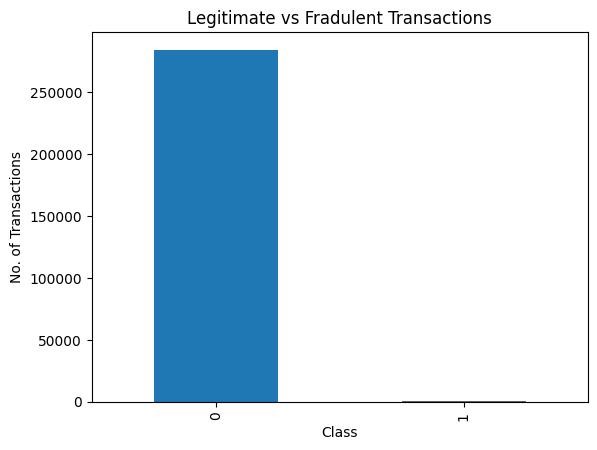

In [214]:
import matplotlib.pyplot as plt

df['Class'].value_counts().plot(kind="bar")
plt.title("Legitimate vs Fradulent Transactions")
plt.xlabel("Class")
plt.ylabel("No. of Transactions")
plt.show()

In [215]:
df["Class"].value_counts(normalize=True) * 100

,proportion
Class,
0,99.827251
1,0.172749


In [216]:
df["Amount"].describe()

,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
25%,5.600000
50%,22.000000
75%,77.165000
max,25691.160000


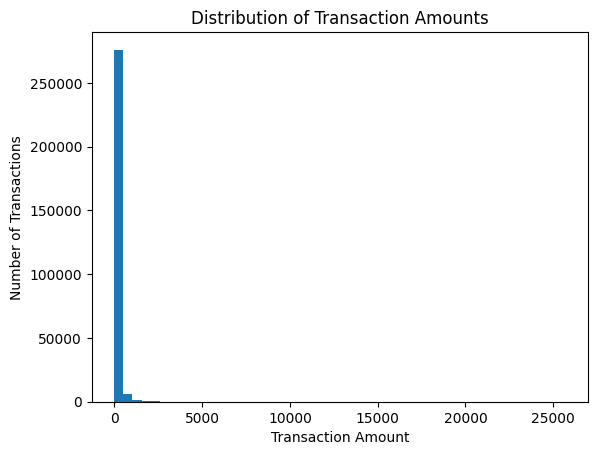

In [217]:
plt.hist(df['Amount'], bins = 50)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()

In [218]:
normal = df[df['Class'] == 0]
fraud = df[df['Class'] == 1]

In [219]:
normal['Amount'].mean()

np.float64(88.29102242231328)

In [220]:
fraud['Amount'].mean()

np.float64(122.21132113821139)

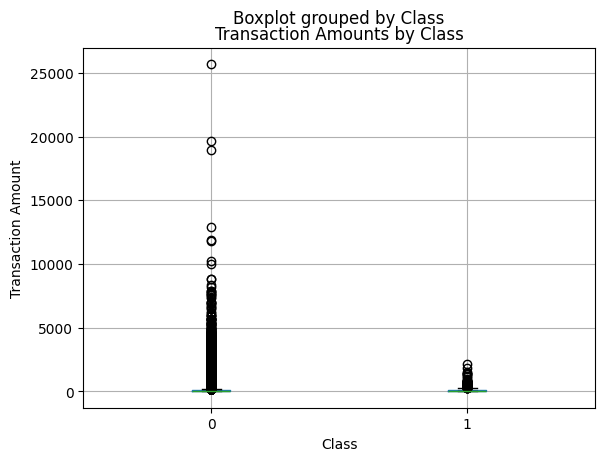

In [221]:
df.boxplot(column = 'Amount', by = 'Class')
plt.title("Transaction Amounts by Class")
plt.xlabel("Class")
plt.ylabel("Transaction Amount")
plt.show()

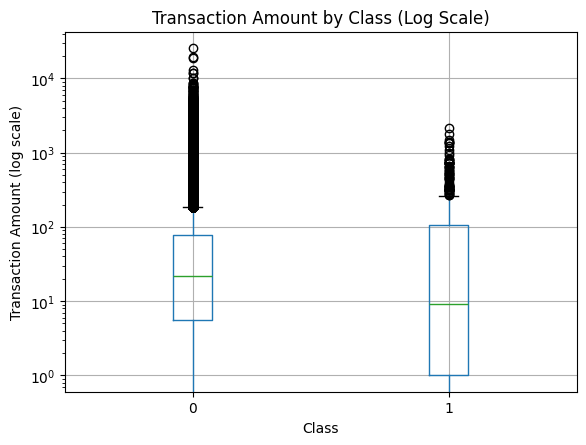

In [222]:
df.boxplot(column="Amount", by="Class")

plt.yscale("log")
plt.title("Transaction Amount by Class (Log Scale)")
plt.suptitle("")
plt.xlabel("Class")
plt.ylabel("Transaction Amount (log scale)")
plt.show()

In [223]:
df.groupby('Class')['Amount'].agg(['mean', 'median', 'min','max'])

,mean,median,min,max
Class,,,,
0,88.291022,22.00,0.0,25691.16
1,122.211321,9.25,0.0,2125.87


In [224]:
df.duplicated().sum()

np.int64(1081)

**Duplicate Records:**

The dataset contained 1,081 duplicate rows. These records were identified using Pandas' `duplicated()` function but were not removed in this baseline version. Their potential impact on model performance was not investigated further and is acknowledged as a limitation of this project.

Initial Data Investigation

- Dataset contains 284,807 transactions.
- There are 31 columns.
- The target variable is Class.
- Class 0 represents legitimate transactions.
- Class 1 represents fraudulent transactions.
- The dataset is highly imbalanced.
- Approximately 0.17% of transactions are fraudulent.
- No missing values were identified.
- Transaction amount distributions were explored for legitimate and fraudulent transactions.

In [225]:
# Making a variable x which has no class column and another variable y which has only Class column
x = df.drop('Class', axis = 1)
y = df['Class']

In [226]:
x.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


In [227]:
y.head()

,Class
0,0
1,0
2,0
3,0
4,0


In [228]:
print(x.shape)
print(y.shape)

(284807, 30)
(284807,)


## 4. Data Preprocessing

Data preprocessing was performed to prepare the dataset for Machine Learning.

### 1. Separating Features and Target

- **X (Features):** Contains the transaction information used by the model to make predictions.
- **y (Target):** Contains the Class column, where 0 represents legitimate transactions and 1 represents fraudulent transactions.

The Class column was removed from X because it is the value the model needs to predict.

### 2. Train-Test Split

The dataset was divided into:

- 80% Training Data – Used to train the model.
- 20% Testing Data – Used to evaluate the model on unseen transactions.

The `stratify=y` parameter was used to maintain the fraud-to-legitimate transaction ratio in both sets.

### 3. Feature Scaling

StandardScaler was used to standardise the Time and Amount columns.

The scaler was fitted only on the training data and then applied to both training and testing data to avoid data leakage.

The V1 to V28 features were not scaled again because they were already transformed numerical features.

### Outcome

The dataset was successfully prepared for training and evaluating the Logistic Regression model.

In [229]:
from sklearn.model_selection import train_test_split

In [230]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [231]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(227845, 30)
(56962, 30)
(227845,)
(56962,)


In [232]:
print(y_train.value_counts())
print(y_test.value_counts())

Class
0    227451
1       394
Name: count, dtype: int64
Class
0    56864
1       98
Name: count, dtype: int64


STEP **5**

In [233]:
from sklearn.preprocessing import StandardScaler

In [234]:
scaler = StandardScaler()

In [235]:
scaler.fit(x_train[["Time", "Amount"]])

StandardScaler()

In [236]:
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

In [237]:
x_train_scaled[["Time", "Amount"]] = scaler.transform(
    x_train[["Time", "Amount"]]
)

x_test_scaled[["Time", "Amount"]] = scaler.transform(
    x_test[["Time", "Amount"]]
)

In [238]:
x_train_scaled[["Time", "Amount"]].head()

,Time,Amount
265518,1.411588,-0.322494
180305,0.623141,-0.339764
42664,-1.130680,0.346693
198723,0.794699,-0.327360
82325,-0.748102,-0.008281


In [239]:
print(x_train_scaled[["Time", "Amount"]].mean())

Time     -1.409578e-16
Amount    3.742243e-17
dtype: float64


In [240]:
print(x_train_scaled[["Time", "Amount"]].std())

Time      1.000002
Amount    1.000002
dtype: float64


In [241]:
#I am first using Logistic Regression to Train patterns to my ML model
from sklearn.linear_model import LogisticRegression

In [242]:
#made a variable model which has Logistic Regrssion tool and it can take maximum 1000 attempts
model = LogisticRegression(max_iter = 1000)

In [243]:
#I am telling the model to learn patterns from training data
model.fit(x_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [244]:
print("My Model has trained itself from the data successfullllY")

My Model has trained itself from the data successfullllY


In [245]:
# I create a new variable which contains Logistic Regression model's predicted data
y_pred = model.predict(x_test_scaled)
print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [246]:
print(y_test[:10])

263020    0
11378     0
147283    0
219439    0
36939     0
243438    0
259448    0
43800     0
66742     0
66499     0
Name: Class, dtype: int64


In [247]:
#I want position (serial no.) of Fraud transactions in test data so that i can compare with model's prediction
#This is not at all useful bcoz these index are from original data and positons have changed when we divided data into test and train
fraud_positions = y_test[y_test == 1].index
print(fraud_positions)

Index([ 77348, 102442, 119781,  48094,  42958,  52584, 204064, 151519, 203324,
       141260,  70589,  14170, 222133, 153835,  14197, 229712,  15810,   8972,
       152019,  30100, 214662,   6717,  18809,  50537,  42696, 151008,  30496,
       150665,   6529,  57615, 157585,   6108,  44556, 142405,    623,  96341,
        40525, 280143, 238366,  68067, 149577, 252774,  64411,  99506,  41569,
       219025, 243699, 102444,  42549,  81186, 141257,  72757, 150647,  42769,
       251477, 249607, 182992, 149600, 243749,  88876,    541, 143728,  42528,
        15476, 105178,  77682,  10204,  16415, 111690,  79536, 149869,  15225,
         6971, 241445,  44001, 251904,  43428,  14211,  42009,  42756, 218442,
       150663,  11343, 106998, 143336,   8312, 238222,  15539,  10497, 154719,
       157918,  83417,   8615, 143333, 119714, 245347, 124176, 181966],
      dtype='int64')


In [248]:
#Let's make a table comparing model's prediction with actual true answers
results = pd.DataFrame({
    "Actual": y_test.values,
    "Prediction": y_pred})

results.head()


,Actual,Prediction
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


In [249]:
results[results["Actual"] == 1]

,Actual,Prediction
840,1,1
1146,1,1
3287,1,1
4276,1,0
5077,1,1
...,...,...
55071,1,1
55247,1,0
56143,1,0
56287,1,0


In [250]:
results = pd.DataFrame({
    "Original_Index": y_test.index,
    "Actual": y_test.values,
    "Prediction": y_pred})

In [251]:
results[results["Actual"] == 1].head(10)

,Original_Index,Actual,Prediction
840,77348,1,1
1146,102442,1,1
3287,119781,1,1
4276,48094,1,0
5077,42958,1,1
5453,52584,1,0
7164,204064,1,0
7299,151519,1,1
7337,203324,1,1
9036,141260,1,1


In [252]:
results[(results['Actual'] == 1) & (results['Prediction'] == 0)]

,Original_Index,Actual,Prediction
4276,48094,1,0
5453,52584,1,0
7164,204064,1,0
9156,70589,1,0
12266,8972,1,0
12588,152019,1,0
16715,18809,1,0
17046,50537,1,0
20971,57615,1,0
20992,157585,1,0


In [253]:
results[(results['Actual']==0) & (results['Prediction'] == 1)]

,Original_Index,Actual,Prediction
2777,14920,0,1
3918,17592,0,1
4973,12229,0,1
20129,13394,0,1
30899,19145,0,1
33633,13405,0,1
38622,13833,0,1
42140,10783,0,1
43275,18125,0,1
46542,170716,0,1


In [254]:
from sklearn.metrics import confusion_matrix

In [255]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[56851    13]
 [   35    63]]


In [256]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [257]:
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy: ', accuracy)

Accuracy:  0.9991573329588147


In [258]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)


print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.8289473684210527
Recall: 0.6428571428571429
F1 Score: 0.7241379310344828


In [259]:
print("MODEL PERFORMANCE")
print("-----------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

MODEL PERFORMANCE
-----------------
Accuracy : 0.9991573329588147
Precision: 0.8289473684210527
Recall   : 0.6428571428571429
F1 Score : 0.7241379310344828


In [260]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[56851    13]
 [   35    63]]


## 5. Model Building – Logistic Regression

Logistic Regression was used to build a binary classification model for detecting fraudulent transactions.

The model was trained using the training dataset and then used to predict whether unseen transactions were legitimate or fraudulent.

- Input: Prepared transaction features (X).
- Output: Predicted class (0 or 1).
- The model was trained using the `fit()` function.
- Predictions were generated using the `predict()` function.

## 6. Model Evaluation

The model was evaluated using the following performance metrics:

| Metric | Score |
|---|---:|
| Accuracy | 99.92% |
| Precision | 82.89% |
| Recall | 64.29% |
| F1 Score | 72.41% |

### Confusion Matrix

| Result | Transactions |
|---|---:|
| True Negative | 56,851 |
| False Positive | 13 |
| False Negative | 35 |
| True Positive | 63 |

### Interpretation

The model correctly detected 63 out of 98 fraudulent transactions, while missing 35.

Although the model achieved high accuracy and reasonably good precision, its recall indicates that further improvement is needed to detect more fraudulent transactions.

Accuracy should be interpreted carefully because the dataset is highly imbalanced.

## 7. Forensic Investigation

Further investigation was conducted to understand the transactions incorrectly classified by the model.

### Key Findings

- 35 actual fraudulent transactions were incorrectly classified as legitimate.
- 13 legitimate transactions were incorrectly flagged as fraudulent.
- The average amount of missed fraud transactions was 175.39, compared with 71.53 for detected fraud transactions.
- Some missed fraud transactions received extremely low predicted fraud probabilities.

### Interpretation

The investigation highlights that the model does not identify every fraudulent transaction. Transaction amount alone does not explain its mistakes, and the transformed features require further investigation.

These findings demonstrate the importance of examining model errors rather than relying only on overall accuracy.

In [261]:
missed_frauds = results[(results['Actual']==1) & (results['Prediction'] == 0)]
print("Number of missed frauds:", len(missed_frauds))

missed_frauds.head(10)

Number of missed frauds: 35


,Original_Index,Actual,Prediction
4276,48094,1,0
5453,52584,1,0
7164,204064,1,0
9156,70589,1,0
12266,8972,1,0
12588,152019,1,0
16715,18809,1,0
17046,50537,1,0
20971,57615,1,0
20992,157585,1,0


In [262]:
missed_fraud_details = df.loc[
    missed_frauds["Original_Index"]
]

missed_fraud_details.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
48094,43494.0,-1.278138,0.716242,-1.143279,0.217805,-1.293890,-1.168952,-2.564182,0.204532,-1.611155,...,0.490183,0.470427,-0.126261,-0.126644,-0.661908,-0.349793,0.454851,0.137843,24.90,1
52584,45541.0,-1.519244,2.308492,-1.503599,2.064101,-1.000845,-1.016897,-2.059731,-0.275166,-1.562206,...,1.307871,0.102826,-0.017746,0.149696,-0.096602,-0.369115,-0.019244,-0.208319,1.00,1
204064,135095.0,0.232512,0.938944,-4.647780,3.079844,-1.902655,-1.041408,-1.020407,0.547069,-1.105990,...,0.911373,1.042929,0.999394,0.901260,-0.452093,0.192959,0.180859,-0.029315,345.00,1
70589,53937.0,-2.042608,1.573578,-2.372652,-0.572676,-2.097353,-0.174142,-3.039520,-1.634233,-0.594809,...,-0.723326,0.501222,-0.696892,-0.600514,0.127547,-0.786072,0.606097,0.171697,261.87,1
8972,12393.0,-4.064005,3.100935,-1.188498,3.264633,-1.903562,0.320351,-0.954940,-3.277535,2.820829,...,1.688665,-0.078845,0.193731,0.479496,-0.506603,-0.409863,-3.036271,-0.630605,179.66,1
152019,96717.0,-3.705856,4.107873,-3.803656,1.710314,-3.582466,1.469729,-9.621560,-11.913105,-0.322297,...,-5.498772,2.941475,0.916236,-0.255504,-0.183835,-0.584539,-0.315484,-0.097223,1.00,1
18809,29785.0,0.923764,0.344048,-2.880004,1.721680,-3.019565,-0.639736,-3.801325,1.299096,0.864065,...,0.899931,1.481271,0.725266,0.176960,-1.815638,-0.536517,0.489035,-0.049729,30.30,1
50537,44532.0,-0.234922,0.355413,1.972183,-1.255593,-0.681387,-0.665732,0.059110,-0.003153,1.122451,...,0.220670,0.912107,-0.286338,0.451208,0.188315,-0.531846,0.123185,0.039581,1.00,1
57615,47982.0,-1.232804,2.244119,-1.703826,1.492536,-1.192985,-1.686110,-1.864612,0.856122,-1.973535,...,0.560475,0.165682,-0.013754,0.474935,-0.218725,0.302809,0.466031,0.250134,0.76,1
157585,110087.0,1.934946,0.650678,-0.286957,3.987828,0.316052,-0.099449,-0.021483,-0.172327,0.508730,...,-0.173602,-0.190974,0.219976,-0.216597,-0.136692,-0.129954,-0.050077,-0.051082,1.00,1


In [263]:
missed_fraud_details[["Time", "Amount", "Class"]].head(10)

,Time,Amount,Class
48094,43494.0,24.90,1
52584,45541.0,1.00,1
204064,135095.0,345.00,1
70589,53937.0,261.87,1
8972,12393.0,179.66,1
152019,96717.0,1.00,1
18809,29785.0,30.30,1
50537,44532.0,1.00,1
57615,47982.0,0.76,1
157585,110087.0,1.00,1


In [264]:
detected_frauds = results[
    (results["Actual"] == 1) &
    (results["Prediction"] == 1)
]

detected_fraud_details = df.loc[
    detected_frauds["Original_Index"]
]

print("Detected frauds:", len(detected_fraud_details))

Detected frauds: 63


In [265]:
print("MISSED FRAUD AMOUNTS")
print(missed_fraud_details["Amount"].describe())

print("\nDETECTED FRAUD AMOUNTS")
print(detected_fraud_details["Amount"].describe())

MISSED FRAUD AMOUNTS
count      35.000000
mean      175.389714
std       357.214030
min         0.000000
25%         1.000000
50%        11.390000
75%       220.440000
max      1809.680000
Name: Amount, dtype: float64

DETECTED FRAUD AMOUNTS
count     63.000000
mean      71.528413
std      106.039778
min        0.000000
25%        1.000000
50%        9.990000
75%       99.990000
max      512.250000
Name: Amount, dtype: float64


In [266]:
# Calculate fraud probabilities
fraud_probabilities = model.predict_proba(x_test_scaled)[:, 1]

# Add probabilities to our results table
results["Fraud_Probability"] = fraud_probabilities

# Show actual frauds with the lowest predicted fraud probability
actual_frauds = results[results["Actual"] == 1]

actual_frauds.sort_values(
    "Fraud_Probability"
).head(10)

,Original_Index,Actual,Prediction,Fraud_Probability
34124,72757,1,0,0.000043
24869,96341,1,0,0.000089
20992,157585,1,0,0.000117
55247,119714,1,0,0.000147
17046,50537,1,0,0.000243
54191,10497,1,0,0.000268
31208,219025,1,0,0.000270
54752,157918,1,0,0.000332
28390,68067,1,0,0.000532
56143,245347,1,0,0.001185


## 8. Conclusion and Future Scope

This project demonstrates the application of Machine Learning to credit card fraud detection using Logistic Regression.

The model achieved 99.92% accuracy, 82.89% precision, 64.29% recall and a 72.41% F1 Score.

The forensic investigation revealed that the model missed 35 actual fraudulent transactions, highlighting the limitations of relying on a single classification model.

### Limitations

- The dataset contains highly imbalanced classes.
- V1 to V28 are anonymised features and cannot be directly interpreted.
- Logistic Regression may not capture every complex fraud pattern.
- The model requires further improvement before any real-world application.

### Future Scope

- Experiment with different classification algorithms.
- Apply threshold tuning to improve fraud detection.
- Compare model performance using Precision, Recall and F1 Score.
- Investigate techniques for handling class imbalance.

### Final Note

This project is an educational prototype intended to demonstrate Machine Learning concepts and forensic analysis. It is not a production-ready fraud detection system.